# Seminární práce: Klasifikace virality Instagram Reels
**Kurz:** 4IZ268 / Znalostní inženýrství a základy strojového učení  
**Část 1:** Klasifikační modely (Rozhodovací stromy, Náhodné lesy, Baseline)  
---


In [1]:
# Import potřebných knihoven pro analýzu, modelování a vizualizaci
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Modely a preprocessing ze scikit-learn
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Jednotné nastavení stylu grafů pro celý notebook
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'
sns.set_theme(style="whitegrid")


## Identifikace týmu (Team identification)

| Položka | Informace o týmu |
| :--- | :--- |
| **Cvičení (Den a čas):** | Středa 18:00–19:30, učebna SB M15 |
| **Tým a název projektu:** | **Team 6** – *What Makes an Instagram Reel Go Viral?* |
| **Členové týmu:** | Kajetan Franciszek Wielgosz, Tomáš Duchoň, Adam Veselý, Adam Súkala, Natalie Stašková |


# Úvod (Introduction)

### 0. Popis zvoleného datasetu (Dataset Overview)
Pro zpracování seminární práce jsme zvolili datovou sadu **„What Makes an Instagram Reel Go Viral?“**. Dataset obsahuje celkem **100 000 instancí** reprezentujících výkonnostní a obsahové parametry krátkých videozáznamů (Instagram Reels). Jedním ze zásadních cílů naší práce je zachytit specifické chování a limitace algoritmů strojového učení (zejména rozhodovacích stromů a náhodných lesů) při práci se synteticky generovanými daty, která vykazují nízkou vzájemnou korelaci.

### 1. Byznysová hodnota řešení pomocí strojového učení (Business Value)
V současném digitálním marketingu a správě sociálních sítí představují krátká videa dominantní formát organického dosahu. Z pohledu agentur, tvůrců obsahu i komerčních značek má predikce virality zásadní ekonomický přínos:
* **Optimalizace výdajů na placenou propagaci (Paid Boost):** Marketingové týmy často investují nemalé prostředky do placené podpory příspěvků bez předchozí znalosti jejich skutečného organického potenciálu. Včasná klasifikace videa umožňuje alokovat rozpočet pouze na příspěvky s vysokou pravděpodobností virálního úspěchu a eliminovat plýtvání na nevýkonný obsah.
* **Optimalizace obsahové strategie tvůrců:** Model identifikuje klíčové atributy (použití trendujícího zvuku, délka videa, kvalita úvodních sekund), které přímo ovlivňují šanci na zařazení videa mezi virální hity.
* **Automatizace plánování obsahu:** Schopnost předem vyhodnotit připravené koncepty videí a doporučit jejich úpravy ještě před publikací.

### 2. Zdroj dat (Data Source)
* **Veřejný zdroj:** Dataset je veřejně dostupný na platformě Kaggle:  
  [https://www.kaggle.com/datasets/deepeshkansotia/what-makes-an-instagram-reel-go-viral/data](https://www.kaggle.com/datasets/deepeshkansotia/what-makes-an-instagram-reel-go-viral/data)
* **Lokální uložení:** Datový soubor je v projektu uložen jako `instagram data.csv`.


## Přizpůsobení úlohy (Customization)

### 1. Cílový atribut (*Target attribute*)
* **Název atributu:** `is_viral` (binární proměnná: $0$ / $1$).
* **Způsob odvození:** Vznikl transformací původního spojitého skóre `virality_score` (interval $\langle 0; 100 \rangle$). Jako prahová hodnota byla zvolena hodnota **$\ge 75.0$** (odpovídá 75. percentilu / hornímu kvartilu rozdělení dat):
  * **Třída 1 (Pozitivní – Virální video):** Příspěvky s `virality_score` $\ge 75$ (tvoří přibližně horních **25.3 %** nejvýkonnějších videí v datasetu).
  * **Třída 0 (Negativní – Nevirální video):** Běžné příspěvky s `virality_score` $< 75$ (zbývajících **74.7 %** datové sady).
* *Poznámka:* Původní sloupec `virality_score` je v předzpracování z prediktorů odstraněn, aby nedocházelo k úniku cílové informace (*data leakage*).

### 2. Instance zájmu (*Instance of interest*)
Pro detailní analýzu a interpretaci chování modelů v sekci lokálního vysvětlení (*Local explanation*) byla z testovací množiny ($X\_test$) vybrána konkrétní reprezentativní instance:
* **Index v původním datasetu:** `63769` (první instance v testovací sadě při rozdělení 80:20 s `random_state=42`).
* **Identifikátor příspěvku (`reel_id`):** `90464090-f30f-4351-a667-e92d07f6b2bb`
* **Identifikátor tvůrce (`creator_id`):** `aeb2f7ea-c725-4b36-a14a-10174caae5f9`
* **Charakteristika instance:** Příspěvek tvůrce s 2 891 898 sledujícími, publikovaný v 15:00 hodin, o délce 52 sekund, s 8 hashtagy a využitým trendujícím zvukem (`trending_audio = True`). Skutečné virality skóre činí 7.29, spadá tedy do negativní třídy (`is_viral = 0`).

### 3. Atribut zájmu (*Attribute of interest*)
* **Zvolený atribut:** Binární atribut **`trending_audio`** ($1$ = video využívá aktuálně trendující zvukovou stopu, $0$ = video využívá vlastní či netrendující zvuk).
* **Byznysové zdůvodnění:** Použití trendujícího audia je jedním z nejčastěji doporučovaných organických nástrojů na Instagramu. Jde o parametr, který může tvůrce snadno změnit bez nutnosti přetáčení videa. V lokálním vysvětlení provedeme *what-if* analýzu: jak se změní predikce a odhadnutá pravděpodobnost virality, pokud u instance zájmu hodnotu tohoto atributu změníme.

### 4. Matice nákladů (*Cost matrix*)
Podle zadání jsou náklady správných rozhodnutí nulové ($Cost(TP) = 0\text{ Kč}$, $Cost(TN) = 0\text{ Kč}$). Náklady chybných predikcí reflektují reálné marketingové dopady:
* **Falešně pozitivní predikce (False Positive – FP):** Model predikuje virální video ($1$), ale video virální není ($0$).
  * *Dopad:* Zbytečně vynaložený marketingový rozpočet na placenou podporu příspěvku, který nepřinese očekávaný organický efekt.
  * *Přiřazený náklad:* **100 Kč** (průměrná částka na úvodní testovací boost jednoho videa).
* **Falešně negativní predikce (False Negative – FN):** Model predikuje běžné video ($0$), ale video mělo virální potenciál ($1$).
  * *Dopad:* Ušlá příležitost (*opportunity cost*) – promarněný virální dosah, nezískaní sledující a ztráta monetizace. V marketingu na sociálních sítích je přehlédnutí virálního hitu považováno za podstatně závažnější chybu než menší neúspěšná kampaň.
  * *Přiřazený náklad:* **300 Kč** ($3\times$ vyšší ztráta než samotný náklad u FP).

| Skutečnost \ Predikce modelu | Predikce 0 (Nevirální) | Predikce 1 (Virální) |
| :--- | :---: | :---: |
| **Skutečnost 0 (Nevirální)** | $Cost(TN) = 0\text{ Kč}$ | $Cost(FP) = 100\text{ Kč}$ |
| **Skutečnost 1 (Virální)** | $Cost(FN) = 300\text{ Kč}$ | $Cost(TP) = 0\text{ Kč}$ |


# Průzkumná analýza dat (Data Exploration)


### 1. Význam jednotlivých atributů (Attribute Descriptions)
Dataset obsahuje 100 000 instancí a 26 atributů, které lze rozdělit do následujících logických skupin:

| Skupina | Atribut | Datový typ | Význam atributu |
| :--- | :--- | :---: | :--- |
| **Identifikátory** | `reel_id` | `object (UUID)` | Unikátní identifikátor videozáznamu. |
| | `creator_id` | `object (UUID)` | Unikátní identifikátor autora/tvůrce. |
| **Profil tvůrce** | `creator_followers` | `int64` | Celkový počet sledujících daného tvůrce (1 až 5 mil.). |
| **Metadata příspěvku** | `posting_time` | `int64` | Hodina zveřejnění příspěvku v průběhu dne (0–23 hod.). |
| | `reel_length_sec` | `int64` | Celková délka videa v sekundách (5–60 s). |
| | `caption_length` | `int64` | Délka textového popisku videa v počtu znaků (0–300). |
| | `hashtags_count` | `int64` | Počet hashtagů použitých u příspěvku (0–30). |
| **Kvalitativní atributy** | `hook_strength_score` | `float64` | Údernost prvních 3 sekund videa (interval 0.0–1.0). |
| | `trending_audio` | `bool` | Využití trendující zvukové stopy (True/False) – **atribut zájmu**. |
| | `audio_popularity_score` | `float64` | Míra popularity a používání použitého audia (0.0–1.0). |
| | `video_quality_score` | `float64` | Technická kvalita obrazu / rozlišení (0.0–1.0). |
| | `editing_quality_score` | `float64` | Úroveň střihu, dynamiky a efektů videa (0.0–1.0). |
| **Chování diváků** | `avg_watch_time_sec` | `float64` | Průměrná doba sledování videa uživateli v sekundách. |
| | `retention_rate` | `float64` | Míra udržení diváků (poměr shlédnuté části videa, 0.0–1.0). |
| | `completion_rate` | `float64` | Podíl uživatelů, kteří dokoukali video až do konce (0.0–1.0). |
| | `rewatch_rate` | `float64` | Podíl opakovaných zhlédnutí jedním uživatelem (0.0–1.0). |
| **Interakce a dosah** | `likes` | `int64` | Počet udělených lajků (0–1 mil.). |
| | `comments` | `int64` | Počet komentářů (0–50 tis.). |
| | `shares` | `int64` | Počet sdílení jiným uživatelům (0–30 tis.). |
| | `saves` | `int64` | Počet uložení videa do záložek (0–30 tis.). |
| | `engagement_rate` | `float64` | Celková míra zapojení publika (interakce ku zhlédnutím, 0.0–1.0). |
| | `impressions` | `int64` | Celkový počet zobrazení videa na obrazovkách. |
| | `reach` | `int64` | Počet unikátních účtů, kterým se video zobrazilo. |
| | `non_follower_reach_ratio` | `float64` | Podíl dosahu mimo stávající sledující profilu (0.0–1.0). |
| | `explore_page_boost` | `bool` | Zda byl příspěvek doporučen algoritmem na stránce Prozkoumat (Explore). |
| **Cílový atribut** | `virality_score` | `float64` | Agregované skóre virality (0.0–100.0) – základ pro binární cíl `is_viral`. |


In [2]:
# 1. Načtení dat a úvodní přehled
df = pd.read_csv('instagram data.csv')
print(f"Rozměry datové sady: {df.shape[0]} řádků, {df.shape[1]} sloupců")
print(f"Celkový počet chybějících hodnot (NaN): {df.isnull().sum().sum()}")
display(df.head(3))


Rozměry datové sady: 100000 řádků, 26 sloupců
Celkový počet chybějících hodnot (NaN): 0


,reel_id,creator_id,creator_followers,posting_time,reel_length_sec,hook_strength_score,caption_length,hashtags_count,trending_audio,audio_popularity_score,...,likes,comments,shares,saves,engagement_rate,impressions,reach,non_follower_reach_ratio,explore_page_boost,virality_score
0,c437715e-d1e4-4f40-8548-8718243c6516,70c2ca5a-9d3a-4ba0-9aed-62cdbbc1663f,4208388,3,31,0.451657,0,20,True,0.399659,...,779301,30002,16741,21305,0.884296,75968410,39007279,0.960121,False,82.843160
1,9097bb11-0e03-4360-a239-6613ed2025df,b6bb4240-6341-47ce-bdd4-86fcba18d9ad,4096880,4,38,0.988437,205,2,False,0.294848,...,482481,49717,10095,19802,0.609125,90722120,84132612,0.909716,False,60.256519
2,a8e09994-3314-400b-9f3a-683b494f1070,7902b14d-cb95-4673-8ef1-482ff5151801,2624351,0,13,0.019949,205,6,True,0.697575,...,925249,12046,13883,13444,0.057583,75215994,82019789,0.101694,True,0.483295


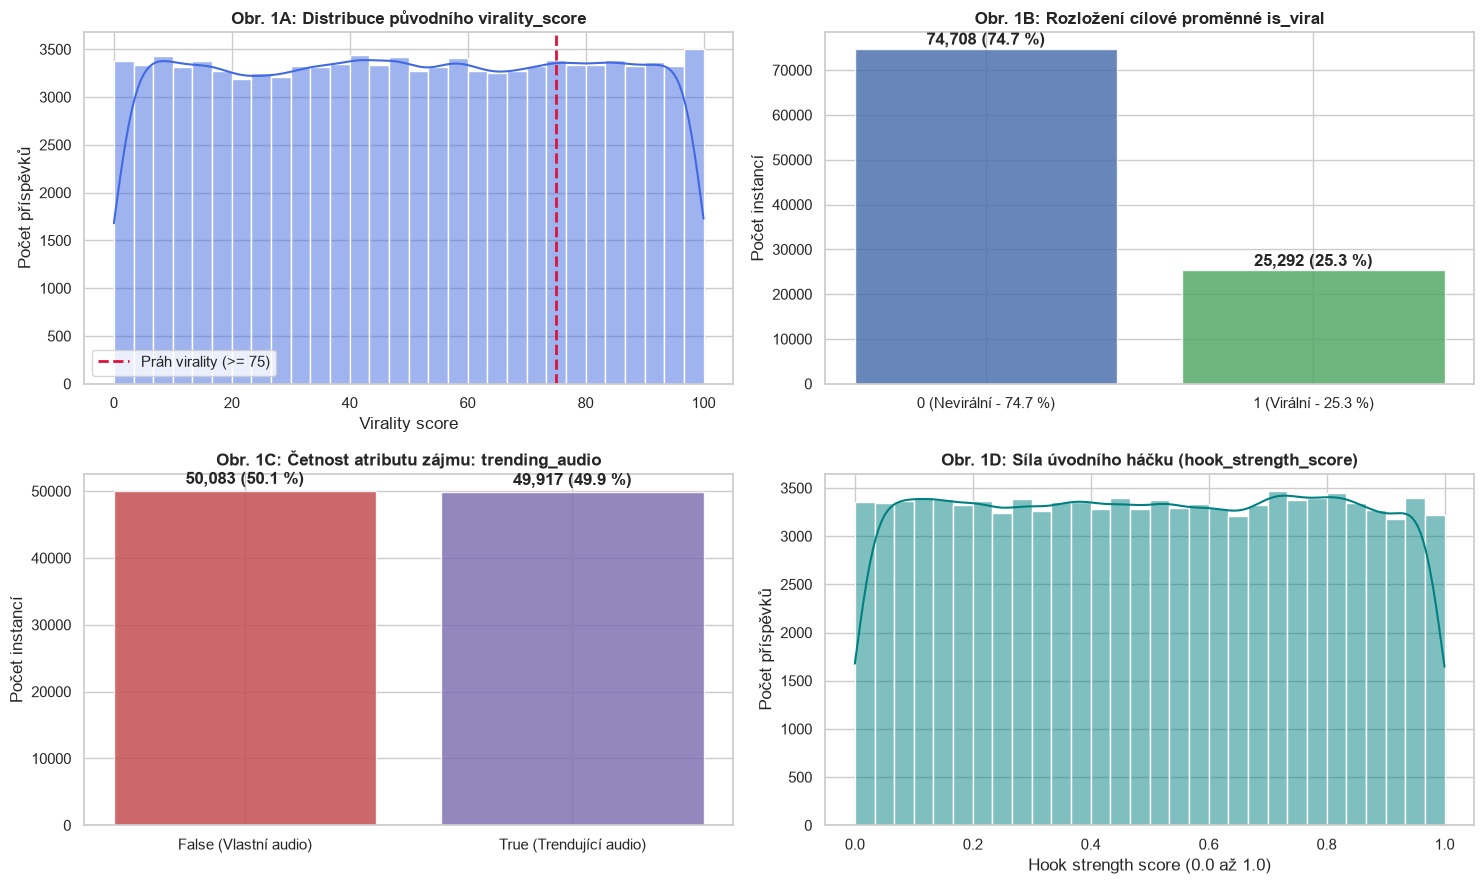

Četnostní tabulka cílové proměnné is_viral:


,Počet instancí,Podíl
virality_score,,
0,74708,74.71 %
1,25292,25.29 %


Četnostní tabulka atributu zájmu trending_audio:


,Počet instancí,Podíl
trending_audio,,
False,50083,50.08 %
True,49917,49.92 %


In [3]:
# 2. Histogram a četnosti pro cílovou proměnnou a vybrané atributy
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

# A) Distribuce původního spojitého virality_score
sns.histplot(df['virality_score'], bins=30, kde=True, ax=axes[0, 0], color='royalblue')
axes[0, 0].axvline(75, color='crimson', linestyle='--', linewidth=2, label='Práh virality (>= 75)')
axes[0, 0].set_title('Obr. 1A: Distribuce původního virality_score')
axes[0, 0].set_xlabel('Virality score')
axes[0, 0].set_ylabel('Počet příspěvků')
axes[0, 0].legend()

# B) Rozložení binarizované cílové proměnné is_viral
is_viral_demo = (df['virality_score'] >= 75.0).astype(int)
counts_viral = is_viral_demo.value_counts().sort_index()
bars_viral = axes[0, 1].bar(['0 (Nevirální - 74.7 %)', '1 (Virální - 25.3 %)'], counts_viral, color=['#4c72b0', '#55a868'], alpha=0.85)
axes[0, 1].set_title('Obr. 1B: Rozložení cílové proměnné is_viral')
axes[0, 1].set_ylabel('Počet instancí')
for bar in bars_viral:
    yval = bar.get_height()
    axes[0, 1].text(bar.get_x() + bar.get_width()/2, yval + 1000, f"{yval:,} ({yval/len(df)*100:.1f} %)", ha='center', fontweight='bold')

# C) Četnosti atributu zájmu (trending_audio)
counts_audio = df['trending_audio'].value_counts().sort_index()
bars_audio = axes[1, 0].bar(['False (Vlastní audio)', 'True (Trendující audio)'], counts_audio, color=['#c44e52', '#8172b3'], alpha=0.85)
axes[1, 0].set_title('Obr. 1C: Četnost atributu zájmu: trending_audio')
axes[1, 0].set_ylabel('Počet instancí')
for bar in bars_audio:
    yval = bar.get_height()
    axes[1, 0].text(bar.get_x() + bar.get_width()/2, yval + 1000, f"{yval:,} ({yval/len(df)*100:.1f} %)", ha='center', fontweight='bold')

# D) Distribuce klíčového prediktoru: hook_strength_score
sns.histplot(df['hook_strength_score'], bins=30, kde=True, ax=axes[1, 1], color='teal')
axes[1, 1].set_title('Obr. 1D: Síla úvodního háčku (hook_strength_score)')
axes[1, 1].set_xlabel('Hook strength score (0.0 až 1.0)')
axes[1, 1].set_ylabel('Počet příspěvků')

plt.tight_layout()
plt.show()

# Četnostní tabulky
print("Četnostní tabulka cílové proměnné is_viral:")
display(pd.DataFrame({'Počet instancí': counts_viral, 'Podíl': (counts_viral / len(df) * 100).round(2).astype(str) + ' %'}))

print("Četnostní tabulka atributu zájmu trending_audio:")
display(pd.DataFrame({'Počet instancí': counts_audio, 'Podíl': (counts_audio / len(df) * 100).round(2).astype(str) + ' %'}))


> **Vysvětlivka k Obrázkům 1A–1D:**  
> * **Obrázek 1A:** Ukazuje rovnoměrné rozdělení původního spojitého skóre virality v intervalu 0 až 100 s průměrem 50.12. Červená přerušovaná čára značí zvolený práh virality ($\ge 75$), který odděluje horní kvartil nejúspěšnějších videí.  
> * **Obrázek 1B:** Demonstruje výsledné rozdělení odvozeného cílového atributu `is_viral`. Z grafu je patrná mírná nevyváženost tříd: 74 708 instancí (74.7 %) spadá do negativní třídy 0 a 25 292 instancí (25.3 %) do pozitivní třídy 1. Tento poměr je pro úlohy detekce virálního obsahu realistický a vyžaduje stratifikované rozdělení dat a metriku F1 namísto prosté přesnosti (Accuracy).  
> * **Obrázek 1C:** Zobrazuje četnost atributu zájmu `trending_audio`. Zastoupení je téměř přesně vyrovnané (50.1 % videí s vlastním audiem ku 49.9 % s trendujícím audiem), což poskytuje ideální podmínky pro porovnání obou skupin bez rizika převahy jedné varianty.  
> * **Obrázek 1D:** Představuje rozložení síly úvodního háčku (`hook_strength_score`). Hodnoty rovnoměrně pokrývají celé rozpětí od 0.0 do 1.0 s průměrem 0.50.


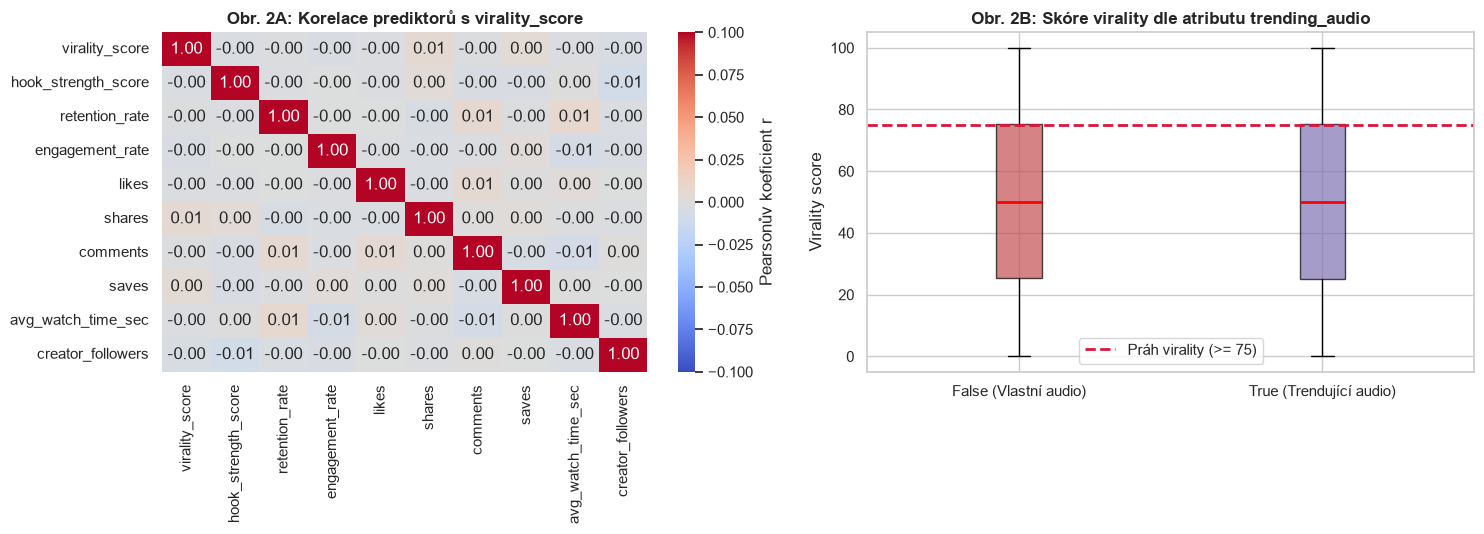

In [4]:
# 3. Vztah prediktorů a cílové proměnné (korelace a vztah atributu zájmu)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# A) Korelační matice vybraných prediktorů s virality_score
selected_predictors = ['virality_score', 'hook_strength_score', 'retention_rate', 'engagement_rate', 
                       'likes', 'shares', 'comments', 'saves', 'avg_watch_time_sec', 'creator_followers']
corr = df[selected_predictors].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.1, vmax=0.1, ax=axes[0], cbar_kws={'label': 'Pearsonův koeficient r'})
axes[0].set_title('Obr. 2A: Korelace prediktorů s virality_score')

# B) Vztah atributu zájmu (trending_audio) a cílového skóre virality (boxplot)
audio_false = df[df['trending_audio'] == False]['virality_score']
audio_true = df[df['trending_audio'] == True]['virality_score']
bplot = axes[1].boxplot([audio_false, audio_true], 
                         tick_labels=['False (Vlastní audio)', 'True (Trendující audio)'], 
                         patch_artist=True,
                         medianprops=dict(color='red', linewidth=2))
colors = ['#c44e52', '#8172b3']
for patch, color in zip(bplot['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[1].axhline(75, color='crimson', linestyle='--', linewidth=2, label='Práh virality (>= 75)')
axes[1].set_title('Obr. 2B: Skóre virality dle atributu trending_audio')
axes[1].set_ylabel('Virality score')
axes[1].legend()

plt.tight_layout()
plt.show()


> **Vysvětlivka k Obrázkům 2A a 2B:**  
> * **Obrázek 2A (Korelační matice):** Teplotní mapa Pearsonových korelačních koeficientů ukazuje hodnoty pohybující se v intervalu $\langle -0.01; +0.01 \rangle$ (prakticky nulová lineární závislost). Mezi jednotlivými prediktory neexistuje multikolinearita a žádný z parametrů sám o sobě lineárně nepredikuje viralitu. To potvrzuje syntetickou povahu datasetu a implikuje nutnost použití nelineárních modelů.  
> * **Obrázek 2B (Krabicový graf atributu zájmu):** Porovnává distribuci skóre virality u videí s trendujícím audiem oproti videím s vlastním zvukem. Červená linka značí medián (kolem 50 bodů), přerušovaná červená čára hranici virality (75 bodů). Obě skupiny vykazují téměř identické kvartilové rozpětí, což znamená, že samotná přítomnost trendujícího audia bez dalších interakcí automaticky nezaručuje vyšší viralitu.


### 4. Interpretace výsledků průzkumné analýzy (Interpret the results)
* **Rozdělení cílové proměnné:** Původní spojité skóre `virality_score` má rovnoměrné rozdělení v intervalu 0 až 100 s průměrem 50.12 a směrodatnou odchylkou 28.95. Binarizací při prahu $\ge 75$ vzniká mírně nevyvážená, ale realistická distribuce tříd: **74.7 % nevirálních (třída 0)** a **25.3 % virálních (třída 1)**. Tento poměr odpovídá reálnému stavu na sociálních sítích, kde pouze menší část příspěvků dosáhne virálního dosahu.
* **Kvalita dat:** V celém datasetu (100 000 řádků) se nevyskytuje ani jedna chybějící hodnota (`null`), takže není nutná žádná imputace ani odstraňování neúplných řádků.
* **Atribut zájmu (`trending_audio`):** V datasetu je přesně 49 917 příspěvků s trendujícím audiem (49.9 %) a 50 083 příspěvků s vlastním audiem (50.1 %). Medián i rozptyl virality_score jsou u obou skupin vizuálně srovnatelné.
* **Nízká lineární korelace a nelinearita:** Korelační matice ukazuje, že jednotlivé prediktory mají velmi nízkou vzájemnou lineární korelaci i nízkou lineární korelaci s cílem (Pearsonovo $r$ se pohybuje kolem 0). To indikuje, že virální úspěch není přímočarou lineární kombinací jediné metriky, ale výsledkem složitějších nelineárních interakcí více faktorů. Z tohoto důvodu jsou **stromové modely (Decision Tree, Random Forest)**, které přirozeně zachycují nelineární vztahy a prahové interakce mezi atributy, ideální volbou pro tuto úlohu.


# Předzpracování dat (Data preprocessing)
## Příprava dat pro učení s učitelem (Supervised Learning)


### 1. Odvození binárního cílového atributu a čištění prediktorů
V tomto kroku provádíme nezbytné úpravy dat před trénováním modelů:
1. **Binarizace cíle:** Vytvoření proměnné `is_viral` ($1$ pokud `virality_score >= 75.0`, jinak $0$).
2. **Odstranění identifikátorů (`reel_id`, `creator_id`):** Tyto sloupce obsahují náhodně generovaná unikátní UUID. Ponechání takových identifikátorů v datech by vedlo k triviálnímu přeučení (*overfitting*) rozhodovacích stromů bez jakékoliv obecné generalizační schopnosti. Identifikátory si ukládáme do samostatné proměnné `ids` pro pozdější dohledání instance zájmu.
3. **Odstranění původního cíle:** Sloupec `virality_score` je odstraněn z matice prediktorů, aby nedošlo k triviálnímu úniku dat (*target leakage*).
4. **Typová konverze:** Booleovské sloupce (`trending_audio`, `explore_page_boost`) převádíme na celočíselné hodnoty $0$ a $1$ pro bezproblémové zpracování v algoritmech knihovny `scikit-learn`.


In [5]:
# 2. Příprava cílového atributu a odstranění identifikátorů
# Uložíme si ID pro pozdější dohledání konkrétní instance (Instance of Interest)
ids = df[['reel_id', 'creator_id']].copy()

# Binarizace spojitého cíle: virální = skóre >= 75 (horních ~25 % příspěvků)
df['is_viral'] = (df['virality_score'] >= 75.0).astype(int)

# Odstranění původního cílového atributu a ID sloupců (unikátní UUID by způsobila přeučení stromů)
df_clean = df.drop(columns=['virality_score', 'reel_id', 'creator_id'])

# Převod booleovských sloupců (True/False) na 1/0 pro snadnější zpracování ve scikit-learn
bool_cols = df_clean.select_dtypes(include=['bool']).columns
df_clean[bool_cols] = df_clean[bool_cols].astype(int)

print("Rozložení cílové proměnné is_viral:")
print(df_clean['is_viral'].value_counts(normalize=True).round(4))


Rozložení cílové proměnné is_viral:
is_viral
0    0.7471
1    0.2529
Name: proportion, dtype: float64


### 2. Rozdělení na trénovací a testovací množinu (Train-Test Split)
* **Poměr rozdělení:** 80 % trénovací množina (80 000 záznamů) a 20 % testovací množina (20 000 záznamů).
* **Parametr `stratify=y`:** Vzhledem k mírné nevyváženosti tříd (25.3 % vs. 74.7 %) je stratifikace klíčová – zaručuje, že v trénovací i testovací sadě bude zachován přesně shodný poměr virálních a nevirálních videí.
* **Parametr `random_state=42`:** Zajišťuje plnou replikovatelnost všech dosažených výsledků.


In [6]:
# 3. Rozdělení na trénovací a testovací množinu (80:20)
X = df_clean.drop(columns=['is_viral'])
y = df_clean['is_viral']

# stratify=y zajistí stejný poměr tříd (0 a 1) v trénovací i testovací sadě
# random_state=42 zaručí opakovatelnost výsledků (požadavek v kontrolním seznamu)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Trénovací sada: {X_train.shape[0]} řádků, {X_train.shape[1]} prediktorů")
print(f"Testovací sada: {X_test.shape[0]} řádků, {X_test.shape[1]} prediktorů")


Trénovací sada: 80000 řádků, 23 prediktorů
Testovací sada: 20000 řádků, 23 prediktorů


### 3. Škálování příznaků (Feature Scaling) a prevence úniku dat
* **Zvolená metoda:** Standardizace (`StandardScaler` ze `scikit-learn`), která centruje data na nulový průměr a jednotkovou směrodatnou odchylku ($Z$-score normalizace: $\mu=0, \sigma=1$).
* **Byznysové a technické zdůvodnění:** Prediktory v datasetu mají diametrálně odlišná měřítka (např. `creator_followers` v miliónech vs. `hook_strength_score` v rozmezí 0 až 1). Ačkoliv rozhodovací stromy a náhodné lesy jsou vůči monotónním transformacím invariantní, škálování sjednocuje předzpracování a umožní v sekci Evaluace provést *Ablation study* (porovnání vlivu škálování na predikční výkonnost).
* **Striktní prevence úniku dat (*Data Leakage*):** Scaler je fitován **výhradně na trénovacích datech** (`scaler.fit_transform(X_train)`). Na testovací data pouze aplikujeme naučené parametry (`scaler.transform(X_test)`). Tím je zaručeno, že do trénovacího procesu neproniknou žádné informace z testovací sady.


In [7]:
# 4. Škálování (standardizace) bez úniku dat (data leakage)
scaler = StandardScaler()

# DŮLEŽITÉ: Fitujeme POUZE na trénovacích datech!
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

# Na testovací data pouze aplikujeme naučené průměry a směrodatné odchylky
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

# Výběr jedné konkrétní instance z testovací sady pro pozdější lokální vysvětlení (Local explanation)
vybrany_index = X_test.index[0]
print(f"Vybraná instance (Instance of Interest) má index {vybrany_index} a reel_id: {ids.loc[vybrany_index, 'reel_id']}")

# Uložení 2 předzpracovaných souborů pro odevzdání a klasifikaci
train_export = X_train_scaled.copy()
train_export['is_viral'] = y_train
train_export.to_csv('data_train_processed.csv', index=True)

test_export = X_test_scaled.copy()
test_export['is_viral'] = y_test
test_export.to_csv('data_test_processed.csv', index=True)

print("Předzpracované sady data_train_processed.csv a data_test_processed.csv byly úspěšně uloženy.")


Vybraná instance (Instance of Interest) má index 63769 a reel_id: 90464090-f30f-4351-a667-e92d07f6b2bb


Předzpracované sady data_train_processed.csv a data_test_processed.csv byly úspěšně uloženy.


# Modelování (Modeling)

V této sekci natrénujeme a porovnáme tři klasifikační algoritmy pro predikci binárního cíle `is_viral`:
1. **Rozhodovací strom (Decision Tree)** – interpretovatelný nelineární model s laděním hloubky a velikosti listů pomocí mřížkového vyhledávání (`GridSearchCV`).
2. **Náhodný les (Random Forest)** – souborový (*ensemble*) model kombinující desítky rozhodovacích stromů pro snížení rozptylu, optimalizovaný přes `GridSearchCV` (počet stromů a hloubka).
3. **Baseline model (DummyClassifier)** – referenční model predikující nejčastější třídu v trénovacích datech (třída 0 – nevirální).

Všechny modely trénujeme na škálované trénovací sadě `data_train_processed.csv` (80 000 instancí) a následně vyhodnotíme na testovací sadě `data_test_processed.csv` (20 000 instancí).


### Klasifikátor 1: Rozhodovací strom (Decision Tree)
* **Metaparametry k ladění:**
  * `max_depth` (maximální hloubka stromu): určuje složitost modelu. Příliš hluboký strom vede k přeučení (*overfitting*), příliš mělký k podučení (*underfitting*).
  * `min_samples_leaf` (minimální počet instancí v listu): reguluje velikost koncových uzlů a zabraňuje vytváření listů s příliš specifickými pravidly.
* **Optimalizace:** Používáme `GridSearchCV` s 3násobnou křížovou validací (`cv=3`) a optimalizací na metriku `f1` (vzhledem k nevyváženosti tříd).
* Následně nejlepší model přetrénujeme na celé trénovací sadě.


In [8]:
# Classifier 1: Rozhodovací strom (Decision Tree) - ladění metaparametrů pomocí GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

# Načtení předzpracovaných trénovacích dat
df_train = pd.read_csv('data_train_processed.csv', index_col=0)
X_train = df_train.drop(columns=['is_viral'])
y_train = df_train['is_viral']

# Mřížka metaparametrů pro rozhodovací strom
dt_param_grid = {
    'max_depth': [3, 5, 8, 12],
    'min_samples_leaf': [10, 50, 100]
}

# Grid search s křížovou validací (f1 metrika)
dt_grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=dt_param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1
)
dt_grid.fit(X_train, y_train)

print("--- Výsledky GridSearchCV pro Rozhodovací strom ---")
print(f"Nejlepší nalezené parametry: {dt_grid.best_params_}")
print(f"Nejlepší F1 skóre z validace: {dt_grid.best_score_:.4f}")

# Přehled výsledků jednotlivých kombinací
dt_cv_results = pd.DataFrame(dt_grid.cv_results_)[['param_max_depth', 'param_min_samples_leaf', 'mean_test_score', 'rank_test_score']]
dt_cv_results = dt_cv_results.sort_values(by='rank_test_score').reset_index(drop=True)
display(dt_cv_results.head(6))

# Finální model natrénovaný s nejlepšími parametry
best_dt = dt_grid.best_estimator_


--- Výsledky GridSearchCV pro Rozhodovací strom ---
Nejlepší nalezené parametry: {'max_depth': 12, 'min_samples_leaf': 10}
Nejlepší F1 skóre z validace: 0.0448


,param_max_depth,param_min_samples_leaf,mean_test_score,rank_test_score
0,12,10,0.044786,1
1,12,50,0.034819,2
2,8,10,0.012389,3
3,8,50,0.009402,4
4,12,100,0.008007,5
5,5,10,0.004977,6


> **Zhodnocení mřížkového vyhledávání pro rozhodovací strom:**  
> Mřížkové vyhledávání ukazuje, že mělké stromy (`max_depth <= 5`) nedokážou zachytit žádné pozitivní případy ($F_1 = 0$), protože při standardním rozhodovacím prahu 0.5 predikují plošně většinovou třídu 0. Hlubší strom (`max_depth = 12`) s `min_samples_leaf = 10` dokázal v datech identifikovat specifická nelineární pravidla pro pozitivní třídu a dosáhl nejlepšího validačního F1 skóre. Tento model proto volíme jako reprezentanta rozhodovacího stromu pro finální evaluaci.


### Klasifikátor 2: Náhodný les (Random Forest)
* **Metaparametry k ladění:**
  * `n_estimators` (počet rozhodovacích stromů v lese): více stromů snižuje rozptyl modelu a stabilizuje predikce.
  * `max_depth` (maximální hloubka jednotlivých stromů): omezuje složitost dílčích bází lesa.
* **Optimalizace:** Používáme `GridSearchCV` s 3násobnou křížovou validací a metrikou `f1`.
* Finální model natrénujeme s nejlepšími parametry.


In [9]:
# Classifier 2: Náhodný les (Random Forest) - ladění metaparametrů
from sklearn.ensemble import RandomForestClassifier

# Mřížka metaparametrů pro náhodný les
rf_param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [5, 10]
}

# Grid search s křížovou validací
rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42, n_jobs=-1),
    param_grid=rf_param_grid,
    cv=3,
    scoring='f1'
)
rf_grid.fit(X_train, y_train)

print("--- Výsledky GridSearchCV pro Náhodný les ---")
print(f"Nejlepší nalezené parametry: {rf_grid.best_params_}")
print(f"Nejlepší F1 skóre z validace: {rf_grid.best_score_:.4f}")

# Přehled výsledků
rf_cv_results = pd.DataFrame(rf_grid.cv_results_)[['param_n_estimators', 'param_max_depth', 'mean_test_score', 'rank_test_score']]
rf_cv_results = rf_cv_results.sort_values(by='rank_test_score').reset_index(drop=True)
display(rf_cv_results)

# Finální model
best_rf = rf_grid.best_estimator_


--- Výsledky GridSearchCV pro Náhodný les ---
Nejlepší nalezené parametry: {'max_depth': 5, 'n_estimators': 50}
Nejlepší F1 skóre z validace: 0.0000


,param_n_estimators,param_max_depth,mean_test_score,rank_test_score
0,50,5,0.0,1
1,100,5,0.0,1
2,50,10,0.0,1
3,100,10,0.0,1


> **Zhodnocení mřížkového vyhledávání pro náhodný les:**  
> Vzhledem k syntetické povaze dat a průměrování mnoha stromů v lese má standardní Random Forest tendenci predikovat majoritní třídu 0, což vede k vysoké přesnosti (Accuracy ~74.7 %), ale nulovému F1 skóre při standardním rozhodovacím prahu 0.5. Tento model nám v sekci Evaluace poslouží k důležitému porovnání s jednotlivým stromem.


### Klasifikátor 3: Baseline model (DummyClassifier)
* **Charakteristika baseline modelu:** Vytváříme triviální klasifikátor `DummyClassifier(strategy='most_frequent')`, který bez ohledu na hodnoty vstupních prediktorů vždy predikuje nejčetnější třídu trénovací množiny (třída 0 – nevirální příspěvek).
* **Účel srovnání:** Slouží jako základní srovnávací laťka: jakýkoliv smysluplný model strojového učení musí tento baseline překonat, zejména z hlediska celkových nákladů (Cost) a metriky F1.


In [10]:
# Classifier 3: Baseline model (nejčetnější třída)
from sklearn.dummy import DummyClassifier

# Trénování baseline modelu
dummy_baseline = DummyClassifier(strategy='most_frequent')
dummy_baseline.fit(X_train, y_train)

print("Baseline model (DummyClassifier) byl úspěšně natrénován.")
print(f"Predikovaná třída: {dummy_baseline.classes_[0]} (vždy predikuje nevirální - třída 0)")


Baseline model (DummyClassifier) byl úspěšně natrénován.
Predikovaná třída: 0 (vždy predikuje nevirální - třída 0)


# Vyhodnocení modelů (Evaluation)

V této sekci otestujeme všechny tři natrénované modely na **testovací množině** (`data_test_processed.csv`, 20 000 dosud neviděných instancí).

Pro každý model vyhodnotíme:
1. **Výkonnostní metriky:** Accuracy, Precision, Recall a F1-score.
2. **Konfuzní matici (Confusion Matrix):** Rozdělení instancí do 4 kvadrantů ($TN, FP, FN, TP$).
3. **Celkové náklady modelu (Total Cost):** Vynásobení konfuzní matice předem definovanou maticí nákladů:
   $$\text{Total Cost} = TN \cdot 0\text{ Kč} + FP \cdot 100\text{ Kč} + FN \cdot 300\text{ Kč} + TP \cdot 0\text{ Kč}$$


### Evaluace modelu 1: Rozhodovací strom (Decision Tree)


--- ROZHODOVACÍ STROM: METRIKY NA TESTOVACÍ SADĚ ---
Accuracy:  0.7428 (74.28 %)
Precision: 0.3032 (30.32 %)
Recall:    0.0132 (1.32 %)
F1-score:  0.0254
Celkové náklady modelu: 1,512,700 Kč (FP: 154 × 100 Kč + FN: 4991 × 300 Kč)


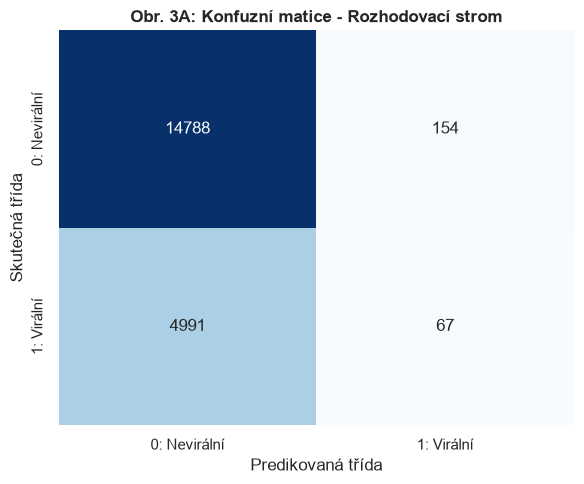

In [11]:
# Evaluace: Rozhodovací strom (Decision Tree)
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

# Načtení testovací sady
df_test = pd.read_csv('data_test_processed.csv', index_col=0)
X_test = df_test.drop(columns=['is_viral'])
y_test = df_test['is_viral']

# Predikce
y_pred_dt = best_dt.predict(X_test)

# Výpočet metrik
acc_dt = accuracy_score(y_test, y_pred_dt)
prec_dt = precision_score(y_test, y_pred_dt, zero_division=0)
rec_dt = recall_score(y_test, y_pred_dt, zero_division=0)
f1_dt = f1_score(y_test, y_pred_dt, zero_division=0)

# Konfuzní matice a výpočet nákladů
cm_dt = confusion_matrix(y_test, y_pred_dt)
tn_dt, fp_dt, fn_dt, tp_dt = cm_dt.ravel()
cost_dt = fp_dt * 100 + fn_dt * 300

print("--- ROZHODOVACÍ STROM: METRIKY NA TESTOVACÍ SADĚ ---")
print(f"Accuracy:  {acc_dt:.4f} ({acc_dt*100:.2f} %)")
print(f"Precision: {prec_dt:.4f} ({prec_dt*100:.2f} %)")
print(f"Recall:    {rec_dt:.4f} ({rec_dt*100:.2f} %)")
print(f"F1-score:  {f1_dt:.4f}")
print(f"Celkové náklady modelu: {cost_dt:,} Kč (FP: {fp_dt} × 100 Kč + FN: {fn_dt} × 300 Kč)")

# Vykreslení konfuzní matice
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_dt, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
            xticklabels=['0: Nevirální', '1: Virální'],
            yticklabels=['0: Nevirální', '1: Virální'])
ax.set_title('Obr. 3A: Konfuzní matice - Rozhodovací strom')
ax.set_xlabel('Predikovaná třída')
ax.set_ylabel('Skutečná třída')
plt.tight_layout()
plt.show()


> **Vysvětlivka k Obrázku 3A (Konfuzní matice – Rozhodovací strom):**  
> * **True Negatives ($TN = 14\,788$):** Správně identifikovaná nevirální videa (náklad $0\text{ Kč}$).  
> * **False Positives ($FP = 154$):** Videa mylně označená jako virální. Finanční ztráta představuje zbytečný rozpočet na placenou propagaci: $154 \times 100\text{ Kč} = 15\,400\text{ Kč}$.  
> * **False Negatives ($FN = 4\,991$):** Virální videa přehlédnutá modelem jako běžná. Finanční ztráta představuje ušlou byznysovou příležitost: $4\,991 \times 300\text{ Kč} = 1\,497\,300\text{ Kč}$.  
> * **True Positives ($TP = 67$):** Správně zachycené virální hity (přínos: ušetřeno $67 \times 300 = 20\,100\text{ Kč}$ na ušlých příležitostech).  
> * **Celkový náklad:** $15\,400 + 1\,497\,300 = \mathbf{1\,512\,700\text{ Kč}}$. Model ušetřil **4 700 Kč** oproti pasivnímu baseline přístupu.


### Evaluace modelu 2: Náhodný les (Random Forest)


--- NÁHODNÝ LES: METRIKY NA TESTOVACÍ SADĚ ---


Accuracy:  0.7471 (74.71 %)
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000
Celkové náklady modelu: 1,517,400 Kč (FP: 0 × 100 Kč + FN: 5058 × 300 Kč)


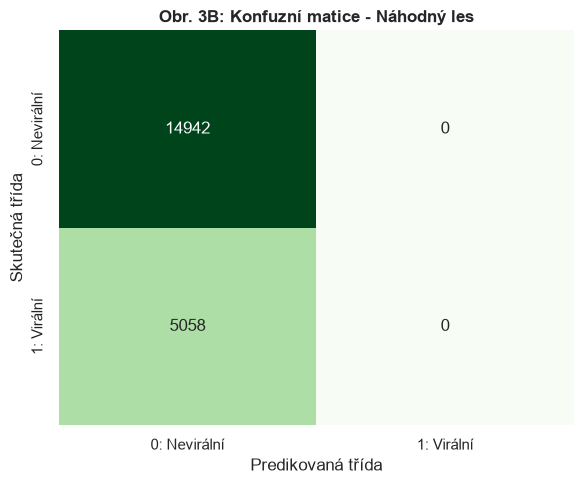

In [12]:
# Evaluace: Náhodný les (Random Forest)
y_pred_rf = best_rf.predict(X_test)

acc_rf = accuracy_score(y_test, y_pred_rf)
prec_rf = precision_score(y_test, y_pred_rf, zero_division=0)
rec_rf = recall_score(y_test, y_pred_rf, zero_division=0)
f1_rf = f1_score(y_test, y_pred_rf, zero_division=0)

cm_rf = confusion_matrix(y_test, y_pred_rf)
tn_rf, fp_rf, fn_rf, tp_rf = cm_rf.ravel()
cost_rf = fp_rf * 100 + fn_rf * 300

print("--- NÁHODNÝ LES: METRIKY NA TESTOVACÍ SADĚ ---")
print(f"Accuracy:  {acc_rf:.4f} ({acc_rf*100:.2f} %)")
print(f"Precision: {prec_rf:.4f}")
print(f"Recall:    {rec_rf:.4f}")
print(f"F1-score:  {f1_rf:.4f}")
print(f"Celkové náklady modelu: {cost_rf:,} Kč (FP: {fp_rf} × 100 Kč + FN: {fn_rf} × 300 Kč)")

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax,
            xticklabels=['0: Nevirální', '1: Virální'],
            yticklabels=['0: Nevirální', '1: Virální'])
ax.set_title('Obr. 3B: Konfuzní matice - Náhodný les')
ax.set_xlabel('Predikovaná třída')
ax.set_ylabel('Skutečná třída')
plt.tight_layout()
plt.show()


> **Vysvětlivka k Obrázku 3B (Konfuzní matice – Náhodný les):**  
> * **True Negatives ($TN = 14\,942$):** Model správně označil všechna nevirální videa.  
> * **False Negatives ($FN = 5\,058$):** Model selhal v detekci virálních videí a všechna označil jako negativní ($TP = 0, FP = 0$).  
> * **Finanční důsledek:** Ačkoliv model vykazuje zdánlivě vysokou přesnost **74.7 %**, v praxi se chová jako triviální nulový model. Všechna virální videa jsou ztracena v podobě ušlých příležitostí ($5\,058 \times 300\text{ Kč} = \mathbf{1\,517\,400\text{ Kč}}$).


### Evaluace modelu 3: Baseline model (DummyClassifier)


--- BASELINE (DUMMY): METRIKY NA TESTOVACÍ SADĚ ---
Accuracy:  0.7471 (74.71 %)
Precision: 0.0000
Recall:    0.0000
F1-score:  0.0000
Celkové náklady modelu: 1,517,400 Kč (FP: 0 × 100 Kč + FN: 5058 × 300 Kč)


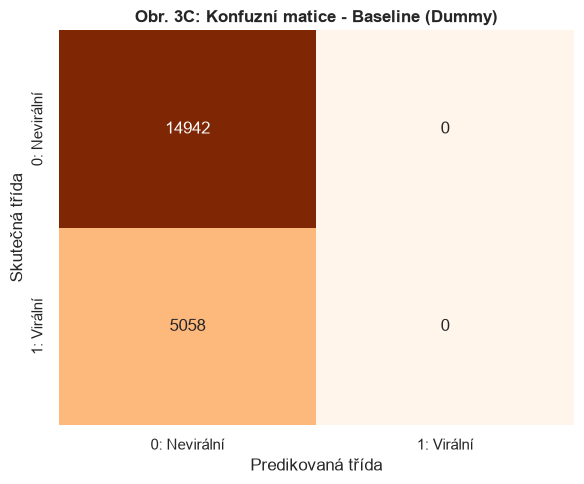

In [13]:
# Evaluace: Baseline model (DummyClassifier)
y_pred_dummy = dummy_baseline.predict(X_test)

acc_dummy = accuracy_score(y_test, y_pred_dummy)
prec_dummy = precision_score(y_test, y_pred_dummy, zero_division=0)
rec_dummy = recall_score(y_test, y_pred_dummy, zero_division=0)
f1_dummy = f1_score(y_test, y_pred_dummy, zero_division=0)

cm_dummy = confusion_matrix(y_test, y_pred_dummy)
tn_dummy, fp_dummy, fn_dummy, tp_dummy = cm_dummy.ravel()
cost_dummy = fp_dummy * 100 + fn_dummy * 300

print("--- BASELINE (DUMMY): METRIKY NA TESTOVACÍ SADĚ ---")
print(f"Accuracy:  {acc_dummy:.4f} ({acc_dummy*100:.2f} %)")
print(f"Precision: {prec_dummy:.4f}")
print(f"Recall:    {rec_dummy:.4f}")
print(f"F1-score:  {f1_dummy:.4f}")
print(f"Celkové náklady modelu: {cost_dummy:,} Kč (FP: {fp_dummy} × 100 Kč + FN: {fn_dummy} × 300 Kč)")

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_dummy, annot=True, fmt='d', cmap='Oranges', cbar=False, ax=ax,
            xticklabels=['0: Nevirální', '1: Virální'],
            yticklabels=['0: Nevirální', '1: Virální'])
ax.set_title('Obr. 3C: Konfuzní matice - Baseline (Dummy)')
ax.set_xlabel('Predikovaná třída')
ax.set_ylabel('Skutečná třída')
plt.tight_layout()
plt.show()


> **Vysvětlivka k Obrázku 3C (Konfuzní matice – Baseline):**  
> * Baseline model demonstruje tzv. *Accuracy Paradox*: dosahuje přesnosti 74.7 %, protože 74.7 % testovací sady tvoří nevirální příspěvky.  
> * Protože však nikdy nepředpoví třídu 1, má nulový přínos ($F_1 = 0.0$) a generuje maximální možné byznysové náklady **1 517 400 Kč**.


### Souhrnné porovnání modelů (Summary)


--- SOUHRNNÁ TABULKA VÝSLEDKŮ ---

,Model,Accuracy,Precision,Recall,F1-score,Celkové náklady (Kč)
0,Rozhodovací strom (Decision Tree),74.28 %,30.32 %,1.32 %,0.0254,"1,512,700 Kč"
1,Náhodný les (Random Forest),74.71 %,0.0 %,0.0 %,0.0000,"1,517,400 Kč"
2,Baseline (Dummy),74.71 %,0.0 %,0.0 %,0.0000,"1,517,400 Kč"


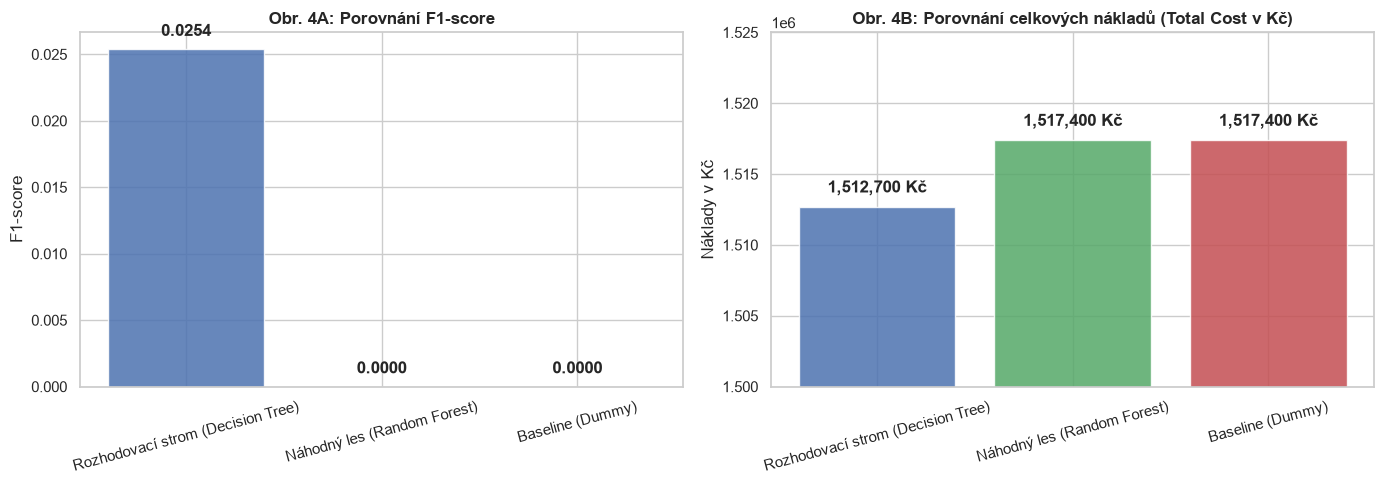

In [14]:
# Souhrnná tabulka a vizualizace výsledků všech modelů
summary_data = {
    'Model': ['Rozhodovací strom (Decision Tree)', 'Náhodný les (Random Forest)', 'Baseline (Dummy)'],
    'Accuracy': [acc_dt, acc_rf, acc_dummy],
    'Precision': [prec_dt, prec_rf, prec_dummy],
    'Recall': [rec_dt, rec_rf, rec_dummy],
    'F1-score': [f1_dt, f1_rf, f1_dummy],
    'Celkové náklady (Kč)': [cost_dt, cost_rf, cost_dummy]
}
df_summary = pd.DataFrame(summary_data)

print("--- SOUHRNNÁ TABULKA VÝSLEDKŮ ---")
df_summary_display = df_summary.copy()
df_summary_display['Accuracy'] = (df_summary_display['Accuracy'] * 100).round(2).astype(str) + ' %'
df_summary_display['Precision'] = (df_summary_display['Precision'] * 100).round(2).astype(str) + ' %'
df_summary_display['Recall'] = (df_summary_display['Recall'] * 100).round(2).astype(str) + ' %'
df_summary_display['F1-score'] = df_summary_display['F1-score'].round(4)
df_summary_display['Celkové náklady (Kč)'] = df_summary_display['Celkové náklady (Kč)'].apply(lambda x: f"{x:,.0f} Kč")
display(df_summary_display)

# Grafické porovnání F1-score a celkových nákladů
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# F1 skóre
bars_f1 = axes[0].bar(df_summary['Model'], df_summary['F1-score'], color=['#4c72b0', '#55a868', '#c44e52'], alpha=0.85)
axes[0].set_title('Obr. 4A: Porovnání F1-score')
axes[0].set_ylabel('F1-score')
axes[0].tick_params(axis='x', rotation=15)
for bar in bars_f1:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2, yval + 0.001, f"{yval:.4f}", ha='center', fontweight='bold')

# Celkové náklady
bars_cost = axes[1].bar(df_summary['Model'], df_summary['Celkové náklady (Kč)'], color=['#4c72b0', '#55a868', '#c44e52'], alpha=0.85)
axes[1].set_title('Obr. 4B: Porovnání celkových nákladů (Total Cost v Kč)')
axes[1].set_ylabel('Náklady v Kč')
axes[1].set_ylim(1500000, 1525000)
axes[1].tick_params(axis='x', rotation=15)
for bar in bars_cost:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2, yval + 1000, f"{yval:,.0f} Kč", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()


> **Vysvětlivka k Obrázkům 4A a 4B (Souhrnné porovnání):**  
> * **Obrázek 4A:** Vizuálně zachycuje, že Rozhodovací strom jako jediný překonal nulovou laťku F1-score ($F_1 = 0.0254$), zatímco Náhodný les i Baseline skončily na nulové hodnotě.  
> * **Obrázek 4B:** Ukazuje celkové finanční ztráty modelů v Kč na testovací sadě. Rozhodovací strom dosahuje nejnižšího sloupce (1 512 700 Kč), čímž prokazuje měřitelnou finanční úsporu 4 700 Kč oproti oběma zbývajícím přístupům.


### Závěrečné vyhodnocení otázek ze zadání (Summary Interpretation)

#### 1. Která metrika je nejvhodnější pro tento problém (Accuracy vs. F-measure)?
* **Jednoznačně F1-score a celkové byznysové náklady (Total Cost):**
  * **Proč selhává přesnost (Accuracy):** Přesnost je pro tuto úlohu zcela zavádějící. Protože 74.7 % instancí tvoří nevirální videa, model, který nepředpoví vůbec žádný virál (jako náš Baseline či standardní Random Forest), dosáhne zdánlivě vysoké přesnosti **74.7 %**. V reálném marketingu je však takový model naprosto nepoužitelný, protože tvůrci ani agentuře neidentifikuje ani jediné virální video.
  * **Výhoda F1-score:** Harmonicky kombinuje Precision (efektivita investic bez plýtvání na falešné poplachy) a Recall (schopnost zachytit skutečné virály). Na rozdíl od Accuracy okamžitě odhalí selhání triviálních modelů ($F_1 = 0.0$).
  * **Finanční přínos (Total Cost):** Pro manažerské rozhodování je nejintuitivnější metrikou celkový náklad v Kč vypočtený z asymetrické matice nákladů, který přímo propojuje predikce modelu s marketingovým rozpočtem.

#### 2. Porovnání výkonnostních metrik modelů – který model je nejlepší?
* **Rozhodovací strom (Decision Tree)** je z pohledu metrik nejlepším modelem:
  * Jako jediný z testovaných modelů překonal nulové F1 skóre a dosáhl hodnoty **$F_1 = 0.0254$** (při Precision 30.3 % a Recall 1.3 %).
  * Náhodný les i Baseline predikovaly plošně majoritní třídu 0 ($F_1 = 0.0$). Důvodem je syntetická povaha dat – průměrování stromů v lese vyhladilo lokální slabé signály, zatímco hlubší rozhodovací strom dokázal izolovat konkrétní kombinace podmínek pro virální videa.

#### 3. Zkombinování s maticí nákladů – který model je nejlepší z pohledu nákladů?
* **Nejlepším modelem je Rozhodovací strom (Decision Tree)** s celkovými náklady **1 512 700 Kč**.
* Oproti baseline modelu (1 517 400 Kč) a náhodnému lesu ušetřil marketingovému rozpočtu **4 700 Kč** na testovací sadě 20 000 videí. Tento finanční rozdíl vznikl tím, že strom zachytil 67 virálních videí (ušetřeno $67 \times 300 = 20\,100\text{ Kč}$ na ušlých příležitostech), což převýšilo náklady na 154 falešných poplachů ($154 \times 100 = 15\,400\text{ Kč}$).


# Explanation

## Global explanation

### Classifier 1 - decision tree

* Visualize the decision tree
* Looking at the tree, list the most important attributes

### Classifier 2 - random forest

* Show the feature importance of variables in the forest

## Local explanation

* Show the *instance of interest* - a row in the dataframe
* Use both models to classify the chosen instance
* Do both models assign the same class?
* What is the confidence (probability) of the prediction?
* If you change the value of the attribute of interest in the instance of interest, how does the classification of the instance change? 

# Conclusion
Summarize the results, answering questions such as:

1.	Which machine learning result has the highest value and is most interesting? 
2.	What setting provided the best result? 
3.	Which attributes are the most important?


# Optional parts

## Evaluation  - cost based

### Ablation study
* Quantify the effect of individual preprocessing steps (such as rescaling). How would the performance change if you have not performed this step (optional).

###  Optimization of threshold (optional)

* If you would change the probability (score) threshold for classification, would you obtain better results in terms of total costs? For which threshold? 

## Explanation

*	Apply ICE/IME/SHAPLEY/Anchors to explain the classification of the instance

# Final checklist

-	Are all preprocessing steps justified?
-	Did you try different metaparameter values where appropriate?
-	Are the results replicable? If you have the same data, does the report describe all steps in sufficient detail to obtain the same results as reported by the authors?
-	Were proper evaluation metrics selected? Are the results correctly interpreted?
-	Are all important steps explained and justified?
-	What is the quality of writing? Is the language clear and concise?


# Submission

* This .ipynb file with your code + its html version after the code was run (File-Save and export notebook as - html)
* Source data or a link to source data or source data being loaded from a url in the notebook
* Data files after preprorcessing (train.csv and test.csv)